# Transformer-to-VLA

## Multimodal Transformer

### 多模态 Token、位置与可见性

---

**目标**

理解图像与文本如何组成一个序列，以及位置、模态标记和 Mask 各自解决什么问题。

**核心概念**

- Patch Embedding
- Text Embedding
- Position / Modality Embedding
- Padding Mask
- Causal / Prefix Mask

**实现**

从程序生成的图像和小词表构造 Token，可视化三种 Attention Mask，并用输入扰动检查 Prefix / Padding Mask 的作用。

**学习重点**

张量形状兼容只是接口条件；信息能否被读取取决于 Mask，语义能力还需要任务训练。


## 1. 环境

本节只做前向计算与机制检查，没有训练语义模型。所有数据在内存中生成。


In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)


PyTorch: 2.14.1+cu130 | Device: cuda


## 2. 从图像和文本生成 Token

图像为 $[B,3,32,32]$ ，用边长为 8 的 Patch 得到 16 个视觉 Token；文本使用 `split()` 和手工词表，不是预训练 LLM 的 tokenizer。沿序列维拼接：

$$
Z=[Z_v;Z_t]\in\mathbb R^{B\times(N_v+N_t)\times D}.
$$

这里 $B=2$ 、 $N_v=16$ 、 $D=32$ ， $N_t$ 是本批次填充后的文本长度。视觉位置向量对应固定的二维网格展平位置；文本位置向量对应词序。可学习的 Modality Embedding 标记信息来源，它不能替代位置编码，也不是所有多模态架构的必需组件。


image: (2, 3, 32, 32) visual: (2, 16, 32)
text: (2, 4, 32) combined: (2, 20, 32)
text IDs: [[4, 2, 0, 0], [1, 2, 3, 5]]


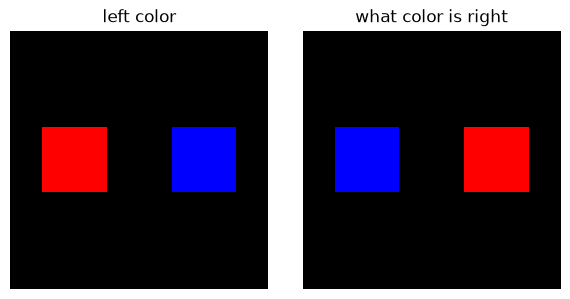

In [2]:
B, D, PATCH_SIZE = 2, 32, 8
images = torch.zeros(B, 3, 32, 32, device=device)
images[0, 0, 12:20, 4:12] = 1.0
images[0, 2, 12:20, 20:28] = 1.0
images[1, 2, 12:20, 4:12] = 1.0
images[1, 0, 12:20, 20:28] = 1.0
vocab = {"<pad>": 0, "what": 1, "color": 2, "is": 3, "left": 4, "right": 5}
sentences = ["left color", "what color is right"]
encoded = [[vocab[word] for word in sentence.split()] for sentence in sentences]
N_TEXT = max(map(len, encoded))
text_ids = torch.zeros(B, N_TEXT, dtype=torch.long, device=device)
for row, ids in enumerate(encoded):
    text_ids[row, :len(ids)] = torch.tensor(ids, device=device)

patch_embed = nn.Conv2d(3, D, PATCH_SIZE, stride=PATCH_SIZE).to(device)
text_embed = nn.Embedding(len(vocab), D, padding_idx=vocab["<pad>"]).to(device)
visual = patch_embed(images).flatten(2).transpose(1, 2)
N_VISUAL = visual.size(1)
visual_pos = nn.Parameter(torch.randn(1, N_VISUAL, D, device=device) * 0.02)
text_pos = nn.Parameter(torch.randn(1, N_TEXT, D, device=device) * 0.02)
modality = nn.Embedding(2, D).to(device)
nn.init.normal_(modality.weight, std=0.02)
visual = visual + visual_pos + modality.weight[0]
text = text_embed(text_ids) + text_pos + modality.weight[1]
text_padding = text_ids.eq(vocab["<pad>"])
combined = torch.cat([visual, text], dim=1)
key_padding = torch.cat([
    torch.zeros(B, N_VISUAL, dtype=torch.bool, device=device), text_padding
], dim=1)
print("image:", tuple(images.shape), "visual:", tuple(visual.shape))
print("text:", tuple(text.shape), "combined:", tuple(combined.shape))
print("text IDs:", text_ids.tolist())
fig, axes = plt.subplots(1, B, figsize=(6, 3))
for i, ax in enumerate(axes):
    ax.imshow(images[i].permute(1, 2, 0).cpu())
    ax.set_title(sentences[i])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. 为什么不用“视觉加 0、文本加 1”作为通用模态编码？

对一个 Token 的所有特征加相同常数，LayerNorm 会消除这个偏移：

$$
\mathrm{LN}(x+c\mathbf{1})=\mathrm{LN}(x).
$$

这是针对直接作用于该向量的 LayerNorm 的数学性质，不代表任意包含 Attention 的整段网络都对该偏移不敏感。下面用浮点误差验证，再与有各维差异的可学习向量比较。本节未训练这些向量，因此也不把非零差异当成语义证据。


In [3]:
probe = torch.randn(4, D, dtype=torch.float64, device=device)
norm = nn.LayerNorm(D).to(device=device, dtype=torch.float64)
constant_delta = (norm(probe + 1) - norm(probe)).abs().max().item()
vector_delta = (norm(probe + modality.weight[1].double()) - norm(probe)).abs().max().item()
assert constant_delta < 1e-10
print("Constant offset after LayerNorm:", constant_delta)
print("Nonuniform modality vector after LayerNorm:", vector_delta)


Constant offset after LayerNorm: 4.440892098500626e-16
Nonuniform modality vector after LayerNorm: 0.045235031106303


## 4. 三种 Mask 表达三种信息可见性

本节沿用 `nn.MultiheadAttention` 的布尔约定：`True` 表示禁止读取。

- **Bidirectional**：有效 Token 彼此可见，适合本章后面的分类任务。
- **Causal**：每个位置只读取自身及之前的位置；直接套在整个拼接序列上，也会限制视觉 Token 之间的交互。
- **Visual-prefix**：视觉前缀内部双向可见，但不能读取文本；文本读取全部视觉前缀和此前／当前文本。

Prefix Mask 只是可见性模板。若训练自回归语言模型，还须将每个文本位置的输出与下一 Token 标签对齐；本节没有语言生成损失。Padding Mask 屏蔽的是 Key，不会自动把 Padding Query 的输出清零。


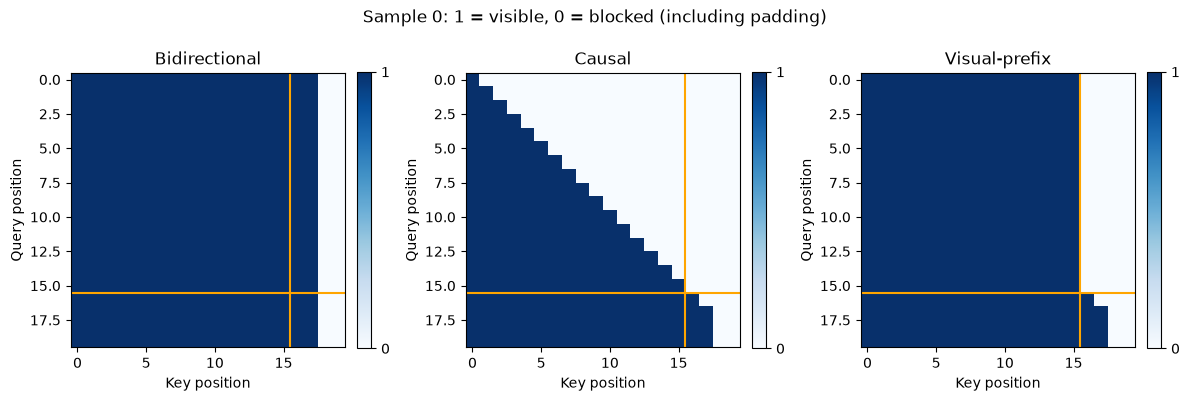

In [4]:
L = N_VISUAL + N_TEXT
bidirectional = torch.zeros(L, L, dtype=torch.bool, device=device)
causal = torch.ones(L, L, dtype=torch.bool, device=device).triu(1)
prefix = torch.ones(L, L, dtype=torch.bool, device=device)
prefix[:N_VISUAL, :N_VISUAL] = False
prefix[N_VISUAL:, :N_VISUAL] = False
prefix[N_VISUAL:, N_VISUAL:] = torch.ones(
    N_TEXT, N_TEXT, dtype=torch.bool, device=device
).triu(1)
masks = {"Bidirectional": bidirectional, "Causal": causal, "Visual-prefix": prefix}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, mask) in zip(axes, masks.items()):
    blocked = mask | key_padding[0].unsqueeze(0)
    im = ax.imshow((~blocked).cpu(), vmin=0, vmax=1, cmap="Blues")
    ax.axvline(N_VISUAL - 0.5, color="orange")
    ax.axhline(N_VISUAL - 0.5, color="orange")
    ax.set(title=name, xlabel="Key position", ylabel="Query position")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=[0, 1])
plt.suptitle("Sample 0: 1 = visible, 0 = blocked (including padding)")
plt.tight_layout()
plt.show()


## 5. 用扰动验证 Mask

检查每个 Head 的被屏蔽权重为零；改变 Padding 内容不应影响有效 Query；改变未来文本不应影响 Prefix Mask 下更早的输出。


In [5]:
attention = nn.MultiheadAttention(D, 4, dropout=0.0, batch_first=True).to(device).eval()
with torch.no_grad():
    output, weights = attention(combined, combined, combined, attn_mask=prefix,
                                key_padding_mask=key_padding, average_attn_weights=False)
    blocked = prefix[None, None] | key_padding[:, None, None, :]
    assert weights.shape == (B, 4, L, L)
    assert weights.masked_select(blocked).eq(0).all()
    assert torch.allclose(weights.sum(-1), torch.ones_like(weights.sum(-1)), atol=1e-6)
    changed_padding = combined.clone()
    changed_padding[key_padding] = 100 * torch.randn_like(changed_padding[key_padding])
    pad_output, _ = attention(changed_padding, changed_padding, changed_padding,
                              attn_mask=prefix, key_padding_mask=key_padding)
    pad_error = (pad_output[~key_padding] - output[~key_padding]).abs().max().item()
    torch.testing.assert_close(pad_output[~key_padding], output[~key_padding])
    changed_future = combined.clone()
    changed_future[1, -1] += torch.randn(D, device=device) * 10
    future_output, _ = attention(changed_future, changed_future, changed_future,
                                 attn_mask=prefix, key_padding_mask=key_padding)
    future_error = (future_output[1, :-1] - output[1, :-1]).abs().max().item()
    torch.testing.assert_close(future_output[1, :-1], output[1, :-1])
print("Per-head weights:", tuple(weights.shape))
print("Padding perturbation / future-token perturbation errors:", pad_error, future_error)
print("Padding-query output norm (not forced to zero):", output[key_padding].norm().item())


Per-head weights: (2, 4, 20, 20)
Padding perturbation / future-token perturbation errors: 0.0 0.0
Padding-query output norm (not forced to zero): 0.2990013360977173


## 6. 小结与练习

- 给文本补充一个有效词，重新检查 Padding Mask 与 Prefix Mask 的形状。
- 改变位置索引，观察它与只改变模态标记有何不同。
- 解释为何“屏蔽 Padding Key”和“训练时忽略 Padding 标签”是两件事。

[项目首页](../README.md) · [上一章](../03_Vision_Transformers/02_Visual_Token_Projection.ipynb) · [下一节：Projector 训练](02_Visual_Language_Projection.ipynb)

参考：[PyTorch MultiheadAttention](https://docs.pytorch.org/docs/2.14/generated/torch.nn.modules.activation.MultiheadAttention.html)、[LayerNorm](https://docs.pytorch.org/docs/2.14/generated/torch.nn.modules.normalization.LayerNorm.html)。
